# TinyAgCNN — Training Notebook
**Input:** 96×96 Grayscale (1 ch)  
**Teacher:** MobileNetV2 (`agroStake-0.1-p2-finetuned.pth`) — PyTorch  
**Student:** TinyAgCNN — TensorFlow  
**Dataset:** `augmented-dataset-96/` — same split as GrapeStake_1_

Flow:
1. Scan dataset → stratified split (identical to GrapeStake)
2. Extract teacher logits once → save as `.npy` (cross-framework bridge)
3. Build `tf.data` pipelines — grayscale student / RGB teacher (already extracted)
4. **Baseline:** normal CE training
5. **Distillation:** KD from teacher logits
6. Eval + confusion matrix + save

## 1 — Imports & Config

In [1]:
!pip install --upgrade typing_extensions


[notice] A new release of pip is available: 26.0.1 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
pip install --upgrade numpy scipy scikit-learn

   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.6 MB ? eta -:--:--
   - -------------------------------------- 1.0/36.6 MB 3.6 MB/s eta 0:00:10
   -- ------------------------------------- 2.6/36.6 MB 5.4 MB/s eta 0:00:07
   ---- ----------------------------------- 3.7/36.6 MB 5.5 MB/s eta 0:00:07
   ------ --------------------------------- 5.5/36.6 MB 6.2 MB/s eta 0:00:06
   ------- -------------------------------- 6.8/36.6 MB 6.2 MB/s eta 0:00:05
   --------- ------------------------------ 8.9/36.6 MB 6.7 MB/s eta 0:00:05
   ------------ --------------------------- 11.3/36.6 MB 7.6 MB/s eta 0:00:04
   -------------- ------------------------- 12.8/36.6 MB 7.7 MB/s eta 0:00:04
   ---------------- ----------------------- 14.9/36.6 MB 7.8 MB/s eta 0:00:03
   ------------------ --------------------- 16.8/36.6 MB 7.9 MB/s eta 0:00:03
   -------------------- ------------------- 18.9/36.6 MB 8.0 MB/s eta 0:00:03
   -----

  You can safely remove it manually.

[notice] A new release of pip is available: 26.0.1 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
# ── Standard ──────────────────────────────────────────────────────────────
import os, sys, random
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score, confusion_matrix, classification_report

# ── TensorFlow ─────────────────────────────────────────────────────────────
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)
print(f'TF device: {"GPU" if gpus else "CPU"}')

# ── PyTorch (teacher only) ─────────────────────────────────────────────────
import torch
import torch.nn as nn
import torchvision.models as tv_models
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets as tv_datasets

torch_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch device: {torch_device}')

TF device: CPU
PyTorch device: cuda


In [6]:
# ── Paths ──────────────────────────────────────────────────────────────────
DATA_ROOT       = '../0_data/augmented-dataset'
TEACHER_WEIGHTS = '../4_models/agroStake-0.1-p2-finetuned.pth'
LOGITS_CACHE    = './teacher_logits_cache.npy'   # extracted once, reused
IDX_CACHE       = './split_indices.npz'          # save split so both runs use the same

# ── Hyper-params ───────────────────────────────────────────────────────────
IMG_SIZE        = 96
NUM_CLASSES     = 4
BATCH_SIZE      = 32
SEED            = 42

# Baseline (normal CE)
BASELINE_EPOCHS = 30
BASELINE_LR     = 1e-3

# Distillation
KD_EPOCHS       = 30
KD_LR           = 1e-3
KD_ALPHA        = 0.5    # weight for hard CE loss
KD_T            = 4.0    # temperature

CLASS_NAMES = ['Black_rot', 'Esca', 'Leaf_blight', 'healthy']  # update if needed

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

## 2 — Dataset Scan & Stratified Split

In [8]:
import os
print(os.getcwd())

c:\Users\xared\Downloads


In [9]:
import os
os.chdir(r'C:\Users\xared\Documents\30_PROJECTS\31_Grapevine_License\2_notebooks')
print(os.getcwd())  # confirm

C:\Users\xared\Documents\30_PROJECTS\31_Grapevine_License\2_notebooks


In [10]:
# Use torchvision ImageFolder just for the sample list & labels
# (same as GrapeStake — guarantees identical class ordering)
full_train_raw = tv_datasets.ImageFolder(root=os.path.join(DATA_ROOT, 'train'))
CLASS_NAMES    = full_train_raw.classes
print(f'Classes: {CLASS_NAMES}')
print(f'Total train samples: {len(full_train_raw)}')

# ── Stratified split — IDENTICAL to GrapeStake_1_ ─────────────────────────
if os.path.exists(IDX_CACHE):
    cache = np.load(IDX_CACHE)
    train_idx = cache['train_idx'].tolist()
    val_idx   = cache['val_idx'].tolist()
    print('Loaded cached split indices.')
else:
    indices = list(range(len(full_train_raw)))
    train_idx, val_idx = train_test_split(
        indices,
        test_size=0.1,
        stratify=full_train_raw.targets,
        random_state=SEED
    )
    np.savez(IDX_CACHE, train_idx=train_idx, val_idx=val_idx)
    print('Split indices saved.')

# Flat lists of (path, label) for each split
all_samples  = full_train_raw.samples   # list of (path, class_idx)
train_samples = [all_samples[i] for i in train_idx]
val_samples   = [all_samples[i] for i in val_idx]

# Test set
test_dir = os.path.join(DATA_ROOT, 'test')
test_raw  = tv_datasets.ImageFolder(root=test_dir)
test_samples = test_raw.samples

print(f'Train: {len(train_samples)} | Val: {len(val_samples)} | Test: {len(test_samples)}')

Classes: ['Black Rot', 'ESCA', 'Healthy', 'Leaf Blight']
Total train samples: 14444
Loaded cached split indices.
Train: 12999 | Val: 1445 | Test: 3610


## 3 — Teacher Logit Extraction (PyTorch MobileNetV2)

In [11]:
# MobileNetV2 architecture must match how it was finetuned in GrapeStake
# Classifier replaced: features → AdaptiveAvgPool → Flatten → Linear(1280,4)

teacher = tv_models.mobilenet_v2(weights=None)
teacher.classifier = nn.Sequential(
    nn.Dropout(p=0.2),
    nn.Linear(teacher.last_channel, NUM_CLASSES)
)
teacher.load_state_dict(torch.load(TEACHER_WEIGHTS, map_location=torch_device))
teacher.eval()
teacher.to(torch_device)
print('Teacher loaded.')

C:\Users\xared\AppData\Local\Temp\ipykernel_28296\2790522418.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  teacher.load_state_dict(torch.load(TEACHER_WEIGHTS, map_loca

Teacher loaded.


In [12]:
# Teacher expects RGB 224×224 (how it was trained in GrapeStake phase-2)
import torchvision.transforms as T

teacher_tf = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225])
])

class RGBDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = cv2.imread(path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = Image_pil(img)  # PIL for torchvision transforms
        if self.transform:
            img = self.transform(img)
        return img, label

# PIL bridge
from PIL import Image as Image_pil_module
def Image_pil(arr): return Image_pil_module.fromarray(arr)

# Reload cell with correct name
class RGBDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = cv2.imread(path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = Image_pil_module.fromarray(img)
        if self.transform:
            img = self.transform(img)
        return img, label

In [13]:
from PIL import Image as Image_pil_module

def extract_logits(samples, teacher, transform, device, batch_size=32, desc='Extracting'):
    """Returns numpy array of shape (N, num_classes) — raw logits."""
    ds = RGBDataset(samples, transform=transform)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=0)
    all_logits = []
    with torch.no_grad():
        for imgs, _ in tqdm(dl, desc=desc):
            imgs = imgs.to(device)
            logits = teacher(imgs)
            all_logits.append(logits.cpu().numpy())
    return np.concatenate(all_logits, axis=0)


# ── Extract & cache ────────────────────────────────────────────────────────
if os.path.exists(LOGITS_CACHE):
    cache_data      = np.load(LOGITS_CACHE, allow_pickle=True).item()
    train_logits    = cache_data['train']
    val_logits      = cache_data['val']
    test_logits     = cache_data['test']
    print(f'Loaded cached logits. Train: {train_logits.shape}')
else:
    train_logits = extract_logits(train_samples, teacher, teacher_tf, torch_device, desc='Train logits')
    val_logits   = extract_logits(val_samples,   teacher, teacher_tf, torch_device, desc='Val logits')
    test_logits  = extract_logits(test_samples,  teacher, teacher_tf, torch_device, desc='Test logits')
    np.save(LOGITS_CACHE, {'train': train_logits, 'val': val_logits, 'test': test_logits})
    print(f'Logits extracted & saved. Train: {train_logits.shape}')

Train logits:   0%|          | 0/407 [00:00<?, ?it/s]

Val logits:   0%|          | 0/46 [00:00<?, ?it/s]

Test logits:   0%|          | 0/113 [00:00<?, ?it/s]

Logits extracted & saved. Train: (12999, 4)


## 4 — TF Data Pipelines (Grayscale 96×96)

In [14]:
def load_grayscale(path, label):
    """Read image → grayscale 96×96 → float32 in [0,1]."""
    raw = tf.io.read_file(path)
    img = tf.image.decode_jpeg(raw, channels=3)          # decode as RGB
    img = tf.image.rgb_to_grayscale(img)                 # (H,W,1)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])     # (96,96,1)
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

def augment(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.15)
    img = tf.image.random_contrast(img, lower=0.85, upper=1.15)
    img = tf.clip_by_value(img, 0.0, 1.0)
    return img, label

# ── Helper: build tf.data from sample list ─────────────────────────────────
def make_dataset(samples, logits=None, augment_fn=None, shuffle=False):
    paths  = [s[0] for s in samples]
    labels = [s[1] for s in samples]

    if logits is not None:
        # Dataset carries (image, label, teacher_logits)
        ds = tf.data.Dataset.from_tensor_slices(
            (paths,
             tf.cast(labels, tf.int32),
             tf.cast(logits, tf.float32))
        )
        ds = ds.map(
            lambda p, l, t: (*load_grayscale(p, l), t),
            num_parallel_calls=tf.data.AUTOTUNE
        )
        if augment_fn:
            ds = ds.map(
                lambda img, lbl, t: (*augment_fn(img, lbl), t),
                num_parallel_calls=tf.data.AUTOTUNE
            )
    else:
        # Normal dataset: (image, label)
        ds = tf.data.Dataset.from_tensor_slices(
            (paths, tf.cast(labels, tf.int32))
        )
        ds = ds.map(load_grayscale, num_parallel_calls=tf.data.AUTOTUNE)
        if augment_fn:
            ds = ds.map(augment_fn, num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        ds = ds.shuffle(buffer_size=len(samples), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

In [15]:
# ── Normal CE pipelines (no teacher logits) ────────────────────────────────
ce_train_ds = make_dataset(train_samples, augment_fn=augment, shuffle=True)
ce_val_ds   = make_dataset(val_samples)
ce_test_ds  = make_dataset(test_samples)

# ── KD pipelines (with teacher logits) ────────────────────────────────────
kd_train_ds = make_dataset(train_samples, logits=train_logits, augment_fn=augment, shuffle=True)
kd_val_ds   = make_dataset(val_samples,   logits=val_logits)
kd_test_ds  = make_dataset(test_samples,  logits=test_logits)

# Quick sanity check
for batch in ce_train_ds.take(1):
    imgs, lbls = batch
    print(f'CE batch — images: {imgs.shape}, labels: {lbls.shape}')

for batch in kd_train_ds.take(1):
    imgs, lbls, tlogits = batch
    print(f'KD batch — images: {imgs.shape}, labels: {lbls.shape}, teacher logits: {tlogits.shape}')

CE batch — images: (32, 96, 96, 1), labels: (32,)
KD batch — images: (32, 96, 96, 1), labels: (32,), teacher logits: (32, 4)


## 5 — Model: TinyAgCNN

In [19]:
def build_TinyAgCNN(input_shape=(96, 96, 1), num_classes=4):
    """
    3× [Conv3×3 VALID → BN → ReLU → MaxPool2] → GAP → Dense(64) → Dense(4)
    Input: (96,96,1) grayscale float32
    Feature map sizes: 96→47→22→10 after each Conv+Pool
    GAP: 10×10×64 → 64 (replaces Flatten 6400 → kills 820k param Dense)
    """
    inputs = tf.keras.Input(shape=input_shape, name='grayscale_input')

    # Block 1 — 96→47
    x = tf.keras.layers.Conv2D(16, 3, strides=1, padding='valid', use_bias=False)(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)
    x = tf.keras.layers.MaxPooling2D(2, strides=2)(x)

    # Block 2 — 47→22
    x = tf.keras.layers.Conv2D(32, 3, strides=1, padding='valid', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)
    x = tf.keras.layers.MaxPooling2D(2, strides=2)(x)

    # Block 3 — 22→10
    x = tf.keras.layers.Conv2D(64, 3, strides=1, padding='valid', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)
    x = tf.keras.layers.MaxPooling2D(2, strides=2)(x)

    # Classifier — GAP replaces Flatten
    x = tf.keras.layers.GlobalAveragePooling2D()(x)   # 64 values
    x = tf.keras.layers.Dense(64, activation='relu')(x)
    outputs = tf.keras.layers.Dense(num_classes, name='logits')(x)

    return tf.keras.Model(inputs, outputs, name='TinyAgCNN')

tmp = build_TinyAgCNN()
tmp.summary()
print(f'\nParam count: {tmp.count_params():,}')

Model: "TinyAgCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ grayscale_input (InputLayer)    │ (None, 96, 96, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 94, 94, 16)     │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 94, 94, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 94, 94, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 47, 47, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 45, 45, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 45, 45, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 22, 22, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 20, 20, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 20, 20, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,052 (109.58 KB)

 Trainable params: 27,828 (108.70 KB)

 Non-trainable params: 224 (896.00 B)


Param count: 28,052


## 6 — Baseline: Normal Cross-Entropy Training

In [20]:
def run_epoch(model, dataset, optimizer=None, training=True):
    """One CE epoch. Returns (loss, recall_macro, all_preds, all_labels)."""
    running_loss = 0.0
    all_preds, all_labels = [], []
    n_batches = 0

    for imgs, labels in dataset:
        if training:
            with tf.GradientTape() as tape:
                logits = model(imgs, training=True)
                loss   = tf.reduce_mean(
                    tf.keras.losses.sparse_categorical_crossentropy(
                        labels, logits, from_logits=True))
            grads = tape.gradient(loss, model.trainable_variables)
            optimizer.apply_gradients(zip(grads, model.trainable_variables))
        else:
            logits = model(imgs, training=False)
            loss   = tf.reduce_mean(
                tf.keras.losses.sparse_categorical_crossentropy(
                    labels, logits, from_logits=True))

        preds = tf.argmax(logits, axis=1).numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
        running_loss += loss.numpy()
        n_batches    += 1

    avg_loss = running_loss / n_batches
    recall   = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    return avg_loss, recall, all_preds, all_labels


def train_baseline(model, train_ds, val_ds, epochs, lr, save_path='best_baseline.keras'):
    optimizer   = tf.keras.optimizers.AdamW(learning_rate=lr)
    best_recall = 0.0
    history     = {'train_loss': [], 'val_loss': [], 'train_recall': [], 'val_recall': []}

    for epoch in range(1, epochs + 1):
        tr_loss, tr_rec, _, _ = run_epoch(model, train_ds, optimizer, training=True)
        vl_loss, vl_rec, _, _ = run_epoch(model, val_ds,   training=False)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(vl_loss)
        history['train_recall'].append(tr_rec)
        history['val_recall'].append(vl_rec)

        marker = ''
        if vl_rec > best_recall:
            best_recall = vl_rec
            model.save(save_path)
            marker = '  ← saved'

        print(f'[Baseline] Epoch {epoch:02d}/{epochs}  '
              f'TrLoss={tr_loss:.4f} TrRec={tr_rec:.4f}  '
              f'VlLoss={vl_loss:.4f} VlRec={vl_rec:.4f}{marker}')

    return history

In [21]:
baseline_model = build_TinyAgCNN()
baseline_history = train_baseline(
    baseline_model,
    ce_train_ds,
    ce_val_ds,
    epochs=BASELINE_EPOCHS,
    lr=BASELINE_LR,
    save_path='best_baseline.keras'
)

[Baseline] Epoch 01/30  TrLoss=1.1139 TrRec=0.5017  VlLoss=3.5125 VlRec=0.2960  ← saved
[Baseline] Epoch 02/30  TrLoss=0.8837 TrRec=0.6273  VlLoss=1.8192 VlRec=0.4439  ← saved
[Baseline] Epoch 03/30  TrLoss=0.8026 TrRec=0.6636  VlLoss=1.2709 VlRec=0.5264  ← saved
[Baseline] Epoch 04/30  TrLoss=0.7649 TrRec=0.6799  VlLoss=1.2149 VlRec=0.5343  ← saved
[Baseline] Epoch 05/30  TrLoss=0.7266 TrRec=0.6975  VlLoss=1.7035 VlRec=0.4111
[Baseline] Epoch 06/30  TrLoss=0.6941 TrRec=0.7126  VlLoss=0.9026 VlRec=0.6401  ← saved
[Baseline] Epoch 07/30  TrLoss=0.6683 TrRec=0.7242  VlLoss=0.8457 VlRec=0.6399
[Baseline] Epoch 08/30  TrLoss=0.6493 TrRec=0.7309  VlLoss=0.8061 VlRec=0.6506  ← saved
[Baseline] Epoch 09/30  TrLoss=0.6286 TrRec=0.7441  VlLoss=1.3010 VlRec=0.5114
[Baseline] Epoch 10/30  TrLoss=0.6045 TrRec=0.7500  VlLoss=2.3468 VlRec=0.4284
[Baseline] Epoch 11/30  TrLoss=0.6009 TrRec=0.7540  VlLoss=0.9730 VlRec=0.6132
[Baseline] Epoch 12/30  TrLoss=0.5935 TrRec=0.7616  VlLoss=2.1945 VlRec=0.491

In [22]:
best_baseline = tf.keras.models.load_model('best_baseline.keras')

In [23]:
from sklearn.metrics import f1_score, accuracy_score

all_preds, all_labels = [], []
for imgs, labels in ce_test_ds:
    logits = best_baseline(imgs, training=False)
    preds  = tf.argmax(logits, axis=1).numpy()
    all_preds.extend(preds)
    all_labels.extend(labels.numpy())

acc = accuracy_score(all_labels, all_preds)
f1  = f1_score(all_labels, all_preds, average='macro')
rec = recall_score(all_labels, all_preds, average='macro')

print(f'Accuracy : {acc:.4f}')
print(f'F1 Macro : {f1:.4f}')
print(f'Recall   : {rec:.4f}')
print()
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

Accuracy : 0.8047
F1 Macro : 0.8118
Recall   : 0.8070

              precision    recall  f1-score   support

   Black Rot       0.64      0.72      0.68       944
        ESCA       0.79      0.81      0.80       960
     Healthy       0.95      0.91      0.93       846
 Leaf Blight       0.90      0.78      0.84       860

    accuracy                           0.80      3610
   macro avg       0.82      0.81      0.81      3610
weighted avg       0.81      0.80      0.81      3610



## 7 — Knowledge Distillation Training

In [24]:
def kd_loss(student_logits, teacher_logits, labels, alpha, T):
    """
    alpha  : weight for hard CE loss  (0 = soft only, 1 = CE only)
    T      : temperature
    Hard loss  : sparse CE(student_logits, ground_truth)
    Soft loss  : KL(teacher_soft || student_soft) * T²
    """
    # Hard
    HL = tf.reduce_mean(
        tf.keras.losses.sparse_categorical_crossentropy(
            labels, student_logits, from_logits=True))

    # Soft
    s_soft = tf.nn.log_softmax(student_logits / T, axis=1)
    t_soft = tf.nn.softmax(teacher_logits  / T, axis=1)
    SL = tf.reduce_mean(
        tf.reduce_sum(
            t_soft * (tf.math.log(t_soft + 1e-8) - s_soft),
            axis=1)) * (T ** 2)

    return alpha * HL + (1.0 - alpha) * SL

In [25]:
def run_kd_epoch(model, dataset, optimizer=None, alpha=0.5, T=4.0, training=True):
    """One KD epoch. Dataset yields (img, label, teacher_logits)."""
    running_loss = 0.0
    all_preds, all_labels = [], []
    n_batches = 0

    for imgs, labels, t_logits in dataset:
        if training:
            with tf.GradientTape() as tape:
                s_logits = model(imgs, training=True)
                loss     = kd_loss(s_logits, t_logits, labels, alpha, T)
            grads = tape.gradient(loss, model.trainable_variables)
            optimizer.apply_gradients(zip(grads, model.trainable_variables))
        else:
            s_logits = model(imgs, training=False)
            loss     = kd_loss(s_logits, t_logits, labels, alpha, T)

        preds = tf.argmax(s_logits, axis=1).numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
        running_loss += loss.numpy()
        n_batches    += 1

    avg_loss = running_loss / n_batches
    recall   = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    return avg_loss, recall, all_preds, all_labels


def train_kd(model, train_ds, val_ds, epochs, lr, alpha, T,
             save_path='best_kd.keras'):
    optimizer   = tf.keras.optimizers.AdamW(learning_rate=lr)
    best_recall = 0.0
    history     = {'train_loss': [], 'val_loss': [], 'train_recall': [], 'val_recall': []}

    for epoch in range(1, epochs + 1):
        tr_loss, tr_rec, _, _ = run_kd_epoch(model, train_ds, optimizer, alpha, T, training=True)
        vl_loss, vl_rec, _, _ = run_kd_epoch(model, val_ds,                alpha, T, training=False)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(vl_loss)
        history['train_recall'].append(tr_rec)
        history['val_recall'].append(vl_rec)

        marker = ''
        if vl_rec > best_recall:
            best_recall = vl_rec
            model.save(save_path)
            marker = '  ← saved'

        print(f'[KD] Epoch {epoch:02d}/{epochs}  '
              f'TrLoss={tr_loss:.4f} TrRec={tr_rec:.4f}  '
              f'VlLoss={vl_loss:.4f} VlRec={vl_rec:.4f}{marker}')

    return history

In [27]:
kd_model = build_TinyAgCNN()
kd_history = train_kd(
    kd_model,
    kd_train_ds,
    kd_val_ds,
    epochs=KD_EPOCHS,
    lr=KD_LR,
    alpha=KD_ALPHA,
    T=KD_T,
    save_path='best_kd.keras'
)

[KD] Epoch 01/30  TrLoss=1.2603 TrRec=0.3309  VlLoss=-1.4850 VlRec=0.3805  ← saved
[KD] Epoch 02/30  TrLoss=1.0992 TrRec=0.4190  VlLoss=6.9462 VlRec=0.2865
[KD] Epoch 03/30  TrLoss=1.0392 TrRec=0.4594  VlLoss=0.4469 VlRec=0.5451  ← saved
[KD] Epoch 04/30  TrLoss=1.0002 TrRec=0.4839  VlLoss=1.4049 VlRec=0.5376
[KD] Epoch 05/30  TrLoss=0.9819 TrRec=0.5020  VlLoss=4.9035 VlRec=0.4134
[KD] Epoch 06/30  TrLoss=0.9617 TrRec=0.5158  VlLoss=-1.9460 VlRec=0.5960  ← saved
[KD] Epoch 07/30  TrLoss=0.9391 TrRec=0.5267  VlLoss=3.8047 VlRec=0.3191
[KD] Epoch 08/30  TrLoss=0.9393 TrRec=0.5274  VlLoss=4.4294 VlRec=0.3259
[KD] Epoch 09/30  TrLoss=0.9273 TrRec=0.5405  VlLoss=-2.9592 VlRec=0.4547
[KD] Epoch 10/30  TrLoss=0.9165 TrRec=0.5468  VlLoss=4.4160 VlRec=0.2708
[KD] Epoch 11/30  TrLoss=0.9076 TrRec=0.5512  VlLoss=0.6322 VlRec=0.5772
[KD] Epoch 12/30  TrLoss=0.9003 TrRec=0.5554  VlLoss=1.4553 VlRec=0.4060
[KD] Epoch 13/30  TrLoss=0.8911 TrRec=0.5682  VlLoss=4.9444 VlRec=0.3748


KeyboardInterrupt: 

## 8 — Evaluation & Comparison

In [28]:
def evaluate_model(model, test_ds, class_names, title='Model'):
    """Runs on CE test_ds (no teacher logits needed)."""
    all_preds, all_labels = [], []

    for batch in test_ds:
        # Handle both (img, lbl) and (img, lbl, logits)
        imgs, labels = batch[0], batch[1]
        logits = model(imgs, training=False)
        preds  = tf.argmax(logits, axis=1).numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

    recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    print(f'\n──────── {title} — Test Set ────────')
    print(f'Macro Recall: {recall:.4f}')
    print(classification_report(all_labels, all_preds, target_names=class_names))

    cm = confusion_matrix(all_labels, all_preds)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'Confusion Matrix — {title}')
    plt.tight_layout()
    plt.savefig(f'cm_{title.replace(" ","_")}.png', dpi=150)
    plt.show()

    return recall, all_preds, all_labels


──────── Baseline CE — Test Set ────────
Macro Recall: 0.8070
              precision    recall  f1-score   support

   Black Rot       0.64      0.72      0.68       944
        ESCA       0.79      0.81      0.80       960
     Healthy       0.95      0.91      0.93       846
 Leaf Blight       0.90      0.78      0.84       860

    accuracy                           0.80      3610
   macro avg       0.82      0.81      0.81      3610
weighted avg       0.81      0.80      0.81      3610



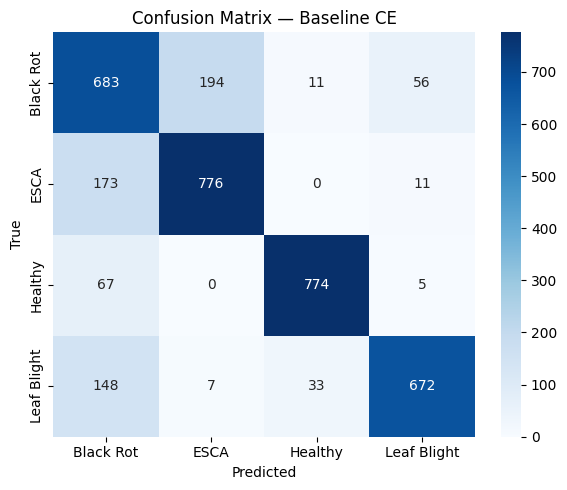


──────── KD — Test Set ────────
Macro Recall: 0.6076
              precision    recall  f1-score   support

   Black Rot       0.49      0.45      0.47       944
        ESCA       0.77      0.39      0.52       960
     Healthy       0.60      0.96      0.74       846
 Leaf Blight       0.60      0.63      0.62       860

    accuracy                           0.60      3610
   macro avg       0.61      0.61      0.59      3610
weighted avg       0.62      0.60      0.58      3610



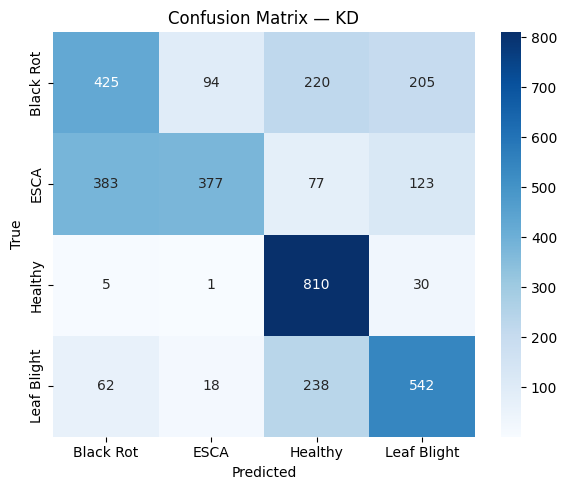

In [29]:
# Load best checkpoints
best_baseline = tf.keras.models.load_model('best_baseline.keras')
best_kd       = tf.keras.models.load_model('best_kd.keras')

bl_recall, _, _ = evaluate_model(best_baseline, ce_test_ds, CLASS_NAMES, title='Baseline CE')
kd_recall, _, _ = evaluate_model(best_kd,       ce_test_ds, CLASS_NAMES, title='KD')

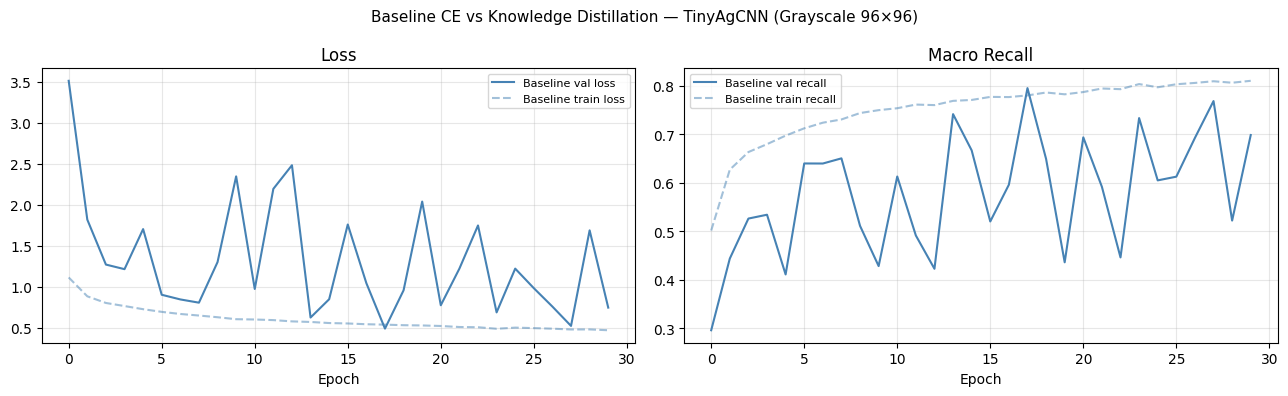


Baseline best val recall: 0.7955

Baseline test recall: 0.8070
KD       test recall: 0.6076


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Loss
ax = axes[0]
ax.plot(baseline_history['val_loss'],  label='Baseline val loss',  color='steelblue')
ax.plot(baseline_history['train_loss'], label='Baseline train loss', color='steelblue', linestyle='--', alpha=0.5)
ax.set_title('Loss')
ax.set_xlabel('Epoch')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Recall
ax = axes[1]
ax.plot(baseline_history['val_recall'],  label='Baseline val recall',  color='steelblue')
ax.plot(baseline_history['train_recall'], label='Baseline train recall', color='steelblue', linestyle='--', alpha=0.5)
ax.set_title('Macro Recall')
ax.set_xlabel('Epoch')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.suptitle('Baseline CE vs Knowledge Distillation — TinyAgCNN (Grayscale 96×96)', fontsize=11)
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()

print(f'\nBaseline best val recall: {max(baseline_history["val_recall"]):.4f}')
print(f'\nBaseline test recall: {bl_recall:.4f}')
print(f'KD       test recall: {kd_recall:.4f}')

## 9 — Export Best Model
Pick whichever scored higher. Save as `.h5` for ESP-DL quantization script.

In [33]:
winner = best_kd if kd_recall >= bl_recall else best_baseline
winner_name = 'KD' if kd_recall >= bl_recall else 'Baseline'
print(f'Winner: {winner_name} (test recall={max(kd_recall, bl_recall):.4f})')

# SavedModel format (for TFLite / ESP-DL conversion)
winner.save('TinyAgCNN_best.keras')

# Also export as TFLite (int8 quantization ready)
converter = tf.lite.TFLiteConverter.from_keras_model(winner)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Representative dataset for full-int8 quantization
def representative_data_gen():
    for imgs, _ in ce_test_ds.take(50):
        for img in imgs:
            yield [tf.expand_dims(img, 0)]

converter.representative_dataset = representative_data_gen
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type  = tf.int8
converter.inference_output_type = tf.int8

tflite_model = converter.convert()
with open('TinyAgCNN_int8.tflite', 'wb') as f:
    f.write(tflite_model)

print(f'TFLite model size: {len(tflite_model)/1024:.1f} KB')
print('Saved: TinyAgCNN_best.keras  |  TinyAgCNN_int8.tflite')

Winner: Baseline (test recall=0.8070)
INFO:tensorflow:Assets written to: C:\Users\xared\AppData\Local\Temp\tmp279rtzwq\assets


INFO:tensorflow:Assets written to: C:\Users\xared\AppData\Local\Temp\tmp279rtzwq\assets


Saved artifact at 'C:\Users\xared\AppData\Local\Temp\tmp279rtzwq'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 96, 96, 1), dtype=tf.float32, name='grayscale_input')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  1577728338128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1577728342928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1577728335632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1577728332560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1577728331984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1577728340240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1577728338320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1577728333328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1577728340432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1577728343504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1577

c:\Users\xared\AppData\Local\Programs\Python\Python311\Lib\site-packages\tensorflow\lite\python\convert.py:997: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


TFLite model size: 36.3 KB
Saved: TinyAgCNN_best.keras  |  TinyAgCNN_int8.tflite


In [34]:
winner.save('TinyAgCNN_best.h5')
print('Saved: TinyAgCNN_best.h5')

Saved: TinyAgCNN_best.h5


In [35]:
import tf2onnx
import tensorflow as tf
import numpy as np

model = tf.keras.models.load_model('best_baseline.keras')

# Convert to ONNX
input_signature = [tf.TensorSpec(shape=(1, 96, 96, 1), dtype=tf.float32, name='grayscale_input')]
onnx_model, _ = tf2onnx.convert.from_keras(model, input_signature=input_signature, opset=13)

import onnx
onnx.save(onnx_model, 'TinyAgCNN.onnx')
print('Saved TinyAgCNN.onnx')

Saved TinyAgCNN.onnx


In [41]:
import torch
import torch.nn as nn
import numpy as np
import tensorflow as tf
import cv2
import os
from torch.utils.data import DataLoader, TensorDataset
from esp_ppq.api import espdl_quantize_torch

# ── 1. Rebuild TinyAgCNN in PyTorch ───────────────────────────────────────
class TinyAgCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=0, bias=False),
            nn.BatchNorm2d(16), nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, 3, padding=0, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, 3, padding=0, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, 4)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

pt_model = TinyAgCNN()

# ── 2. Transfer weights from Keras ────────────────────────────────────────
keras_model = tf.keras.models.load_model('best_baseline.keras')

keras_layers = [l for l in keras_model.layers if len(l.get_weights()) > 0]
print('Keras layers with weights:')
for i, l in enumerate(keras_layers):
    print(f'  {i}: {l.name} — {[w.shape for w in l.get_weights()]}')

# Map: Conv(0,3,6) → BN(1,4,7) → Dense(9,10)
# Conv: Keras (H,W,in,out) → PyTorch (out,in,H,W)
pt_convs = [pt_model.features[0], pt_model.features[4], pt_model.features[8]]
pt_bns   = [pt_model.features[1], pt_model.features[5], pt_model.features[9]]
pt_denses = list(pt_model.classifier.children())
pt_denses = [m for m in pt_model.classifier if isinstance(m, nn.Linear)]

for i, (pt_conv, pt_bn) in enumerate(zip(pt_convs, pt_bns)):
    # Conv weight
    k_conv_w = keras_layers[i*2].get_weights()[0]        # (H,W,in,out)
    pt_conv.weight.data = torch.tensor(
        k_conv_w.transpose(3, 2, 0, 1), dtype=torch.float32)  # (out,in,H,W)
    # BN: gamma, beta, moving_mean, moving_var
    k_bn_w = keras_layers[i*2+1].get_weights()
    pt_bn.weight.data       = torch.tensor(k_bn_w[0], dtype=torch.float32)
    pt_bn.bias.data         = torch.tensor(k_bn_w[1], dtype=torch.float32)
    pt_bn.running_mean.data = torch.tensor(k_bn_w[2], dtype=torch.float32)
    pt_bn.running_var.data  = torch.tensor(k_bn_w[3], dtype=torch.float32)

# Dense layers (Keras index 6 and 7)
for i, pt_dense in enumerate(pt_denses):
    k_dense_w, k_dense_b = keras_layers[6+i].get_weights()
    pt_dense.weight.data = torch.tensor(k_dense_w.T, dtype=torch.float32)
    pt_dense.bias.data   = torch.tensor(k_dense_b,   dtype=torch.float32)

pt_model.eval()

# ── 3. Verify transfer ─────────────────────────────────────────────────────
dummy = np.random.rand(1, 96, 96, 1).astype(np.float32)
keras_out = keras_model.predict(dummy, verbose=0)
pt_out    = pt_model(torch.tensor(dummy.transpose(0,3,1,2))).detach().numpy()
print(f'Keras out: {keras_out}')
print(f'PyTorch out: {pt_out}')
print(f'Max diff: {np.abs(keras_out - pt_out).max():.6f}')  # should be <0.01

# ── 4. Calibration dataset — NCHW ─────────────────────────────────────────
CALIB_DIR = '../0_data/augmented-dataset/test'

def load_calib_images(root, n=256):
    imgs = []
    for cls in sorted(os.listdir(root)):
        cls_dir = os.path.join(root, cls)
        if not os.path.isdir(cls_dir): continue
        for fname in sorted(os.listdir(cls_dir))[:n//4]:
            img = cv2.imread(os.path.join(cls_dir, fname), cv2.IMREAD_GRAYSCALE)
            img = cv2.resize(img, (96, 96)).astype(np.float32) / 255.0
            imgs.append(img)
    arr = np.array(imgs)[:, np.newaxis, :, :]  # (N,1,96,96) NCHW
    return torch.tensor(arr)

calib_images  = load_calib_images(CALIB_DIR)
calib_loader  = DataLoader(TensorDataset(calib_images), batch_size=8, shuffle=False)

def collate_fn(batch):
    return batch[0]

# ── 5. Quantize ────────────────────────────────────────────────────────────
quant_graph = espdl_quantize_torch(
    model             = pt_model,
    espdl_export_file = './TinyAgCNN_s8.espdl',
    calib_dataloader  = calib_loader,
    calib_steps       = 32,
    input_shape       = [1, 1, 96, 96],
    target            = 'esp32s3',
    num_of_bits       = 8,
    collate_fn        = collate_fn,
    device            = 'cpu',
    error_report      = True,
    export_test_values= True,
    verbose           = 1,
)

print('Done → TinyAgCNN_s8.espdl')

Keras layers with weights:
  0: conv2d_9 — [(3, 3, 1, 16)]
  1: batch_normalization_9 — [(16,), (16,), (16,), (16,)]
  2: conv2d_10 — [(3, 3, 16, 32)]
  3: batch_normalization_10 — [(32,), (32,), (32,), (32,)]
  4: conv2d_11 — [(3, 3, 32, 64)]
  5: batch_normalization_11 — [(64,), (64,), (64,), (64,)]
  6: dense_3 — [(64, 64), (64,)]
  7: logits — [(64, 4), (4,)]
Keras out: [[ 0.71405303 -1.4875766   6.759768   -4.502868  ]]
PyTorch out: [[ 1.8009497 -3.6456442 12.312738  -7.3068056]]
Max diff: 5.552970
[22:09:19] ConvTranspose Decomposition Pass Running ... Finished.
[22:09:20] PPQ Quantization Fusion Pass Running ...       Finished.
[22:09:20] PPQ Quantize Simplify Pass Running ...         Finished.
[22:09:20] PPQ Parameter Quantization Pass Running ...    Finished.
[22:09:20] PPQ Runtime Calibration Pass Running ...       

Calibration Progress(Phase 2): 100%|██████████| 32/32 [00:00<00:00, 44.95it/s]


Finished.
[22:09:22] PPQ Quantization Alignment Pass Running ...    Finished.
[22:09:22] PPQ Passive Parameter Quantization Running ... Finished.
--------- Network Snapshot ---------
Num of Op:                    [14]
Num of Quantized Op:          [14]
Num of Variable:              [25]
Num of Quantized Var:         [25]
------- Quantization Snapshot ------
Num of Quant Config:          [38]
ACTIVATED:                    [12]
OVERLAPPED:                   [21]
PASSIVE:                      [5]
Network Quantization Finished.


Analysing Graphwise Quantization Error(Phrase 1):: 100%|██████████| 8/8 [00:00<00:00, 39.57it/s]
Analysing Graphwise Quantization Error(Phrase 2):: 100%|██████████| 8/8 [00:00<00:00, 22.27it/s]


Layer                          | NOISE:SIGNAL POWER RATIO 
/classifier/classifier.2/Gemm: | ████████████████████ | 53.930%
/classifier/classifier.0/Gemm: | █                    | 4.245%
/features/features.8/Conv:     | █                    | 2.521%
/features/features.0/Conv:     |                      | 0.639%
/features/features.4/Conv:     |                      | 0.564%


Analysing Layerwise quantization error:: 100%|██████████| 5/5 [00:01<00:00,  4.58it/s]


Layer                          | NOISE:SIGNAL POWER RATIO 
/features/features.0/Conv:     | ████████████████████ | 42.186%
/features/features.4/Conv:     |                      | 1.062%
/classifier/classifier.2/Gemm: |                      | 0.055%
/features/features.8/Conv:     |                      | 0.048%
/classifier/classifier.0/Gemm: |                      | 0.024%
Done → TinyAgCNN_s8.espdl
